# Is momentum real? Does the team that kicked the last goal kick the next one?

Commentators talk about momentum all the time: a team kicks a goal, "has the
momentum", and is expected to kick the next one too. AFL Tables' scoring
progression lists every goal in order, so we can check.

**Question** ([pre-registered plan](../docs/preregistration_momentum.md)): if a
team kicked the last goal, is it more likely to kick the next one than you'd
expect from the two teams' goal totals alone? And after kicking the last two?

**Definitions**
- **Goals only.** Behinds are ignored, so a behind between two goals doesn't break a run.
- **Runs reset each quarter.** The first goal of a quarter has no previous goal.
- **Repeat rate:** the share of goals kicked by the same team that kicked the previous goal
  (test 1), or the previous two goals (test 2).

**Data:** every 2025 and 2026 match (home-and-away and finals), parsed by
`src/afl/scoring.py`. Each match's summed points are checked against its scoreboard.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from afl.analysis import bootstrap
from afl.draft_charts import BLUE, GREY, INK, ORANGE, TITLE, apply_style
from afl.scoring import season_scoring

YEARS = [2025, 2026]
N_SHUFFLES = 1000
N_BOOT = 2000
SEED = 2026
apply_style()

loaded = [season_scoring(year) for year in YEARS]
events = pd.concat([e.assign(season=y) for (e, _), y in zip(loaded, YEARS)], ignore_index=True)
quarters = pd.concat([q.assign(season=y) for (_, q), y in zip(loaded, YEARS)], ignore_index=True)

matches = quarters.drop_duplicates("match")
print(f"Matches: {len(matches)}; summed points match the scoreboard in all of them: {matches['valid'].all()}")

# Goals only, in the order AFL Tables lists them (chronological within each quarter)
goals = events[events["kind"] == "goal"].reset_index(drop=True)
out_of_order = goals.groupby(["match", "quarter"])["seconds"].apply(lambda s: (s.diff() < 0).sum()).sum()
print(f"Goals: {len(goals):,}; goals listed out of time order: {out_of_order}")

Matches: 434; summed points match the scoreboard in all of them: True
Goals: 10,941; goals listed out of time order: 0


## 1. Why not just compare with 50%?

Better teams kick more goals. If one team kicks 60% of a match's goals and the
order is completely random, the same team still kicks consecutive goals
0.6 × 0.6 + 0.4 × 0.4 = **52%** of the time. So 50% is the wrong benchmark.

Instead, each match is compared with **random reorderings of its own goals**:

- Shuffle which team kicked each of the match's goals, keeping each team's total
  and the number of goals in each quarter.
- Recompute the repeat rate. Do that 1,000 times.
- The average is the **expected repeat rate**: what we'd see if the order of
  goals within a match were pure chance.

Momentum shows up as an **observed repeat rate above the expected one**.

In [2]:
def after_run(teams, quarter, k):
    """Goals that follow k goals in a row by one team in the same quarter.

    teams:   1 if the home team kicked the goal, else 0, in match order. Either one
             ordering (1-D) or many shuffled orderings, one per row (2-D).
    quarter: the quarter of each goal (1-D, never shuffled).
    Returns (number of such goals, number kicked by the team on the run).
    """
    n = teams.shape[-1]
    # Goal i qualifies if goals i-k ... i-1 were all kicked by one team, in i's quarter.
    # Goals are in order, so i and i-k in the same quarter means all of them are.
    same_quarter = quarter[k:] == quarter[:n - k]
    qualifies = np.broadcast_to(same_quarter, teams[..., k:].shape)  # one copy per ordering
    for j in range(1, k):
        qualifies = qualifies & (teams[..., k - j:n - j] == teams[..., k - j - 1:n - j - 1])
    repeats = qualifies & (teams[..., k:] == teams[..., k - 1:n - 1])
    return qualifies.sum(axis=-1), repeats.sum(axis=-1)


# A tiny check: home, home, away | (new quarter) away, away, away
check = after_run(np.array([1, 1, 0, 0, 0, 0]), np.array([1, 1, 1, 2, 2, 2]), k=1)
print("After one goal (expect 4 goals, 3 repeats):", check)
print("After two goals (expect 2 goals, 1 repeat):", after_run(np.array([1, 1, 0, 0, 0, 0]), np.array([1, 1, 1, 2, 2, 2]), k=2))

After one goal (expect 4 goals, 3 repeats): (np.int64(4), np.int64(3))
After two goals (expect 2 goals, 1 repeat): (np.int64(2), np.int64(1))


For each match: count the qualifying goals and repeats as they actually
happened, then in each of 1,000 shuffles. Stored as arrays with one column per
match, so any group of matches (a season, a bootstrap resample) can be summed later.

In [3]:
RUNS = [1, 2, 3]  # after one, two and three goals in a row (three is descriptive only)
rng = np.random.default_rng(SEED)
match_ids = goals["match"].unique()
observed = {k: np.zeros((2, len(match_ids)), dtype=int) for k in RUNS}             # [goals, repeats] x match
shuffled = {k: np.zeros((2, N_SHUFFLES, len(match_ids)), dtype=int) for k in RUNS}  # [goals, repeats] x shuffle x match

for m, (_, g) in enumerate(goals.groupby("match", sort=False)):
    teams = (g["team"] == g["home"]).to_numpy().astype(int)
    quarter = g["quarter"].to_numpy()
    shuffles = rng.permuted(np.tile(teams, (N_SHUFFLES, 1)), axis=1)  # each row: one random reordering
    for k in RUNS:
        observed[k][:, m] = after_run(teams, quarter, k)
        shuffled[k][:, :, m] = np.stack(after_run(shuffles, quarter, k))

season_of = goals.drop_duplicates("match").set_index("match").loc[match_ids, "season"].to_numpy()
for k in RUNS:
    print(f"After {k} goal(s) in a row: {observed[k][0].sum():,} goals")

After 1 goal(s) in a row: 9,207 goals
After 2 goal(s) in a row: 3,972 goals
After 3 goal(s) in a row: 1,709 goals


In [4]:
def rates(idx, k):
    """Observed and expected repeat rates (%), pooled over the matches in idx."""
    obs_goals, obs_repeats = observed[k][:, idx].sum(axis=1)
    shuf_goals, shuf_repeats = shuffled[k][:, :, idx].sum(axis=2)
    return 100 * obs_repeats / obs_goals, 100 * (shuf_repeats / shuf_goals).mean()


def excess(idx, k):
    """Observed minus expected repeat rate, in percentage points."""
    obs, exp = rates(idx, k)
    return obs - exp


def verdict(low, high):
    """Pre-registered two-sided reading of a 95% interval for the excess."""
    if low > 0:
        return "momentum (interval above 0)"
    if high < 0:
        return "anti-momentum (interval below 0)"
    return "inconclusive (interval includes 0)"


def summarise(idx, k):
    """One row: sample size, observed and expected rates, and the bootstrapped excess."""
    # Resample matches; each resample recomputes observed and expected from its own matches
    est, low, high = bootstrap(pd.DataFrame({"i": idx}), lambda d: excess(d["i"].to_numpy(), k), n=N_BOOT, seed=SEED)
    obs, exp = rates(idx, k)
    return {"goals": observed[k][0, idx].sum(), "observed %": obs, "expected %": exp,
            "excess (pts)": est, "low": low, "high": high, "reading": verdict(low, high)}

## 2. Primary tests

Test 1: after the team kicked the last goal. Test 2: after it kicked the last
two. 95% bootstrap intervals resample whole matches (2,000 resamples).

In [5]:
everything = np.arange(len(match_ids))
primary = pd.DataFrame({f"Test {k}: after {k} goal{'s' if k > 1 else ''}": summarise(everything, k) for k in [1, 2]}).T
# Size in plain terms: extra back-to-back goals per match, beyond what chance gives
obs_repeats = observed[1][1].sum()
expected_repeats = shuffled[1][1].sum(axis=1).mean()
print(f"Extra back-to-back goals: {obs_repeats - expected_repeats:.0f} over {len(match_ids)} matches, "
      f"or {(obs_repeats - expected_repeats) / len(match_ids):.2f} per match")
primary.round(2)

Extra back-to-back goals: 124 over 434 matches, or 0.29 per match


,goals,observed %,expected %,excess (pts),low,high,reading
Test 1: after 1 goal,9207,52.709895,51.359031,1.350863,0.414744,2.278202,momentum (interval above 0)
Test 2: after 2 goals,3972,54.884189,52.716544,2.167645,0.823912,3.604358,momentum (interval above 0)


Shuffled seasons with a repeat rate at least as high as the real one: 0.5%


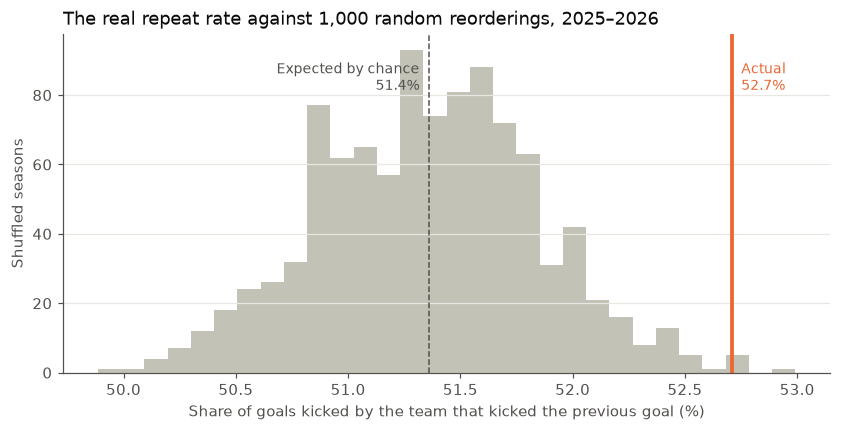

In [6]:
# What chance alone looks like for test 1: the pooled repeat rate in each of the 1,000 shuffled seasons
shuf_goals, shuf_repeats = shuffled[1].sum(axis=2)
shuffled_rates = 100 * shuf_repeats / shuf_goals
obs1, exp1 = rates(everything, 1)
share_at_least = (shuffled_rates >= obs1).mean()
print(f"Shuffled seasons with a repeat rate at least as high as the real one: {share_at_least:.1%}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(shuffled_rates, bins=30, color=GREY)
ax.axvline(exp1, color=INK, linewidth=1, linestyle="--")
ax.axvline(obs1, color=ORANGE, linewidth=2.5)
ax.annotate(f"Expected by chance\n{exp1:.1f}%", (exp1, 0.92), xycoords=("data", "axes fraction"),
            xytext=(-6, 0), textcoords="offset points", ha="right", va="top", fontsize=9, color=INK)
ax.annotate(f"Actual\n{obs1:.1f}%", (obs1, 0.92), xycoords=("data", "axes fraction"),
            xytext=(6, 0), textcoords="offset points", ha="left", va="top", fontsize=9, color=ORANGE)
ax.set_xlabel("Share of goals kicked by the team that kicked the previous goal (%)")
ax.set_ylabel("Shuffled seasons")
ax.grid(axis="x", visible=False)
ax.set_title("The real repeat rate against 1,000 random reorderings, 2025–2026", loc="left", color=TITLE)
plt.show()

## 3. After one, two and three goals in a row

Three in a row wasn't a pre-registered test (the sample is smaller). It's shown
to see whether any pattern builds with longer runs. The dashed line is 50%: the
gap between it and the grey dots is how much team strength alone lifts the repeat rate.

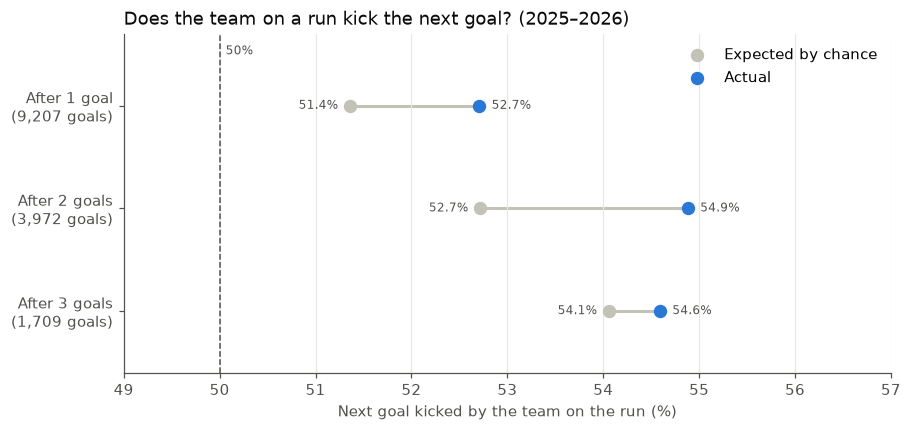

,goals,observed %,expected %,excess (pts),low,high,reading
goals in a row,,,,,,,
1,9207,52.709895,51.359031,1.350863,0.414744,2.278202,momentum (interval above 0)
2,3972,54.884189,52.716544,2.167645,0.823912,3.604358,momentum (interval above 0)
3,1709,54.593329,54.059253,0.534076,-1.61252,2.682502,inconclusive (interval includes 0)


In [7]:
by_run = pd.DataFrame({k: summarise(everything, k) for k in RUNS}).T
by_run.index.name = "goals in a row"

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(RUNS))[::-1]
for yi, (k, row) in zip(y, by_run.iterrows()):
    exp, obs = row["expected %"], row["observed %"]
    ax.plot([exp, obs], [yi, yi], color=GREY, linewidth=2, zorder=1)
    ax.scatter(exp, yi, s=60, color=GREY, zorder=2, label="Expected by chance" if k == 1 else None)
    ax.scatter(obs, yi, s=60, color=BLUE, zorder=3, label="Actual" if k == 1 else None)
    left, right = sorted([(exp, GREY), (obs, BLUE)])
    ax.annotate(f"{left[0]:.1f}%", (left[0], yi), xytext=(-8, 0), textcoords="offset points",
                ha="right", va="center", fontsize=8, color=INK)
    ax.annotate(f"{right[0]:.1f}%", (right[0], yi), xytext=(8, 0), textcoords="offset points",
                ha="left", va="center", fontsize=8, color=INK)
ax.axvline(50, color=INK, linewidth=1, linestyle="--")
ax.annotate("50%", (50, len(RUNS) - 0.5), xytext=(4, 0), textcoords="offset points", fontsize=8, color=INK)
ax.set_yticks(y, [f"After {k} goal{'s' if k > 1 else ''}\n({n:,} goals)" for k, n in zip(RUNS, by_run["goals"])])
ax.set_xlim(49, 57)
ax.set_ylim(-0.6, len(RUNS) - 0.3)
ax.set_xlabel("Next goal kicked by the team on the run (%)")
ax.grid(axis="y", visible=False)
ax.set_title("Does the team on a run kick the next goal? (2025–2026)", loc="left", color=TITLE)
ax.legend(frameon=False, loc="upper right")
plt.show()
by_run.round(2)

## 4. Secondary: each season separately

With two seasons, the time-on analysis (notebook 07) showed how easily one
season's pattern disappears. Here each season gets the same tests.

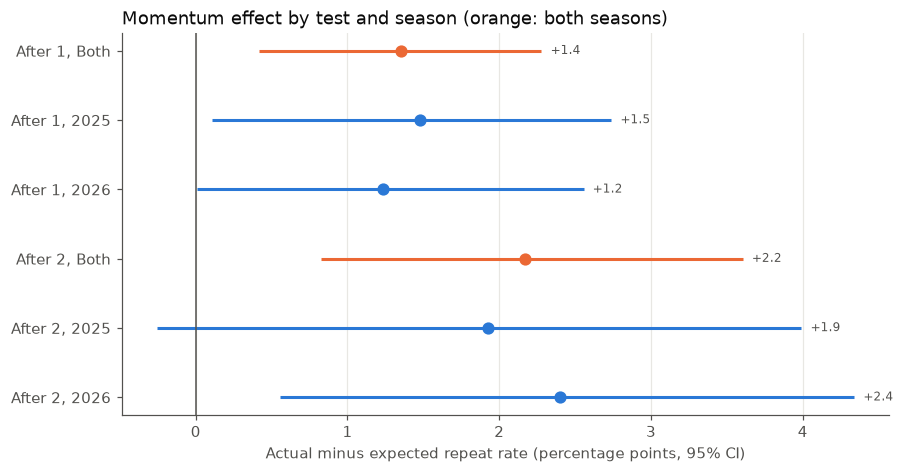

,test,season,goals,observed %,expected %,excess (pts),low,high,reading
0,After 1,Both,9207,52.71,51.36,1.35,0.41,2.28,momentum (interval above 0)
1,After 1,2025,4434,53.13,51.66,1.48,0.11,2.74,momentum (interval above 0)
2,After 1,2026,4773,52.32,51.08,1.24,0.01,2.56,momentum (interval above 0)
3,After 2,Both,3972,54.88,52.72,2.17,0.82,3.60,momentum (interval above 0)
4,After 2,2025,1905,55.22,53.30,1.92,-0.26,3.99,inconclusive (interval includes 0)
5,After 2,2026,2067,54.57,52.17,2.40,0.56,4.34,momentum (interval above 0)


In [8]:
rows = []
for k in [1, 2]:
    rows.append({"test": f"After {k}", "season": "Both", **summarise(everything, k)})
    for year in YEARS:
        rows.append({"test": f"After {k}", "season": str(year), **summarise(np.flatnonzero(season_of == year), k)})
seasons = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(seasons))[::-1]
for yi, (_, row) in zip(y, seasons.iterrows()):
    colour = ORANGE if row["season"] == "Both" else BLUE
    ax.errorbar(row["excess (pts)"], yi, xerr=[[row["excess (pts)"] - row["low"]], [row["high"] - row["excess (pts)"]]],
                fmt="o", color=colour, markersize=7, capsize=0, elinewidth=2)
    ax.annotate(f"{row['excess (pts)']:+.1f}", (row["high"], yi), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(y, [f"{t}, {s}" for t, s in zip(seasons["test"], seasons["season"])])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Actual minus expected repeat rate (percentage points, 95% CI)")
ax.set_title("Momentum effect by test and season (orange: both seasons)", loc="left", color=TITLE)
plt.show()
seasons.round(2)

# Results

## Data

- **All 434 matches of 2025 and 2026**, every one matching its scoreboard:
  **10,941 goals**, none listed out of time order.
- **9,207 goals** had a previous goal in the same quarter (test 1), and
  **3,972** followed two goals in a row by one team (test 2), as in the pre-registration.

## Primary tests: momentum is real, but small

- **Test 1, after kicking the last goal:** the same team kicked the next goal
  **52.7%** of the time, against **51.4%** expected by chance. That's
  **+1.4 percentage points (95% CI +0.4 to +2.3): momentum**, by the
  pre-registered rule.
- **Test 2, after kicking the last two goals:** **54.9%** against **52.7%**
  expected: **+2.2 points (CI +0.8 to +3.6): momentum.**
- **In plain terms:** about **124 extra back-to-back goals over 434 matches**,
  or **0.29 a match**. That's roughly one extra back-to-back goal every three or
  four games.
- Only 0.5% of the 1,000 shuffled seasons reached the real repeat rate in test 1.
  (Not pre-registered; it's another way of showing the same result.)

## Does it build with longer runs?

- **Not clearly.** The estimate after two goals (+2.2) is higher than after one
  (+1.4), but the intervals overlap heavily. After three goals in a row
  (descriptive only, 1,709 goals) it drops to **+0.5 (CI −1.6 to +2.7)**.

## Secondary checks

- **Comparing with 50% would double the effect.** Team strength alone lifts
  the expected repeat rate to 51.4%, so a naive comparison would report
  +2.7 points instead of +1.4.
- **Both seasons point the same way:**
  - Test 1: **+1.5** in 2025 (CI +0.1 to +2.7) and **+1.2** in 2026 (CI +0.0 to +2.6).
  - Test 2: **+1.9** in 2025 (CI −0.3 to +4.0) and **+2.4** in 2026 (CI +0.6 to +4.3).

  Unlike the teams' time-on edges in notebook 07, the estimates are similar in both seasons.

## What it means

- **Goals bunch together a little more than chance would produce.** A team that
  has just kicked a goal kicks the next one about 53% of the time, when chance
  would give 51%.
- **That's an upper bound on true momentum, not proof of it.** The shuffle only
  holds each team's *whole-match* goal total fixed. Anything that makes a team
  better for part of a match also bunches its goals, including the wind, an
  injury or a tactical change. So "momentum" here means "teams have
  good and bad patches within a match", not necessarily that the last goal
  causes the next.

**Deviations from the pre-registration:** none in the tests. The share of
shuffled seasons and the goals-per-match figure were added to help explain the
result.